# Replication: Mid-Atlantic Ridge and Magellan Seamounts

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
import seafloor as sf

REGIONS = {
    "Mariana (original)": dict(west=140.0, east=148.0, south=9.0, north=15.0),
    "Mid-Atlantic Ridge": dict(west=-48.0, east=-40.0, south=24.0, north=30.0),
    "Magellan Seamounts": dict(west=150.0, east=158.0, south=13.0, north=19.0),
}

def load_region(reg):
    lon, lat, z = sf.load(reg)
    _, _, zm = sf.load(reg, layer="topo-mask")
    ship = ~np.isnan(zm) if zm.shape == z.shape else None
    resid = z - ndimage.median_filter(z, size=5)
    land = z >= 0
    bad = (np.abs(resid) > 500) | land | (ndimage.binary_dilation(land, iterations=2) & ~land)
    z = z.copy(); z[bad] = np.nan
    dx, dy = sf.cell_size_m(lon, lat)
    return lon, lat, z, ship, dx, dy

data = {}
for name, reg in REGIONS.items():
    try:
        data[name] = load_region(reg)
        lon, lat, z, ship, dx, dy = data[name]
        cov = f"{ship[~np.isnan(z)].mean():.0%} ship-measured" if ship is not None else "no ship mask"
        print(f"{name:20s} grid {z.shape}, cell ≈ {np.mean(dx):.0f} m, median depth {np.nanmedian(z):,.0f} m, {cov}")
    except Exception as e:
        print(f"{name:20s} FAILED: {e}")

Mariana (original)   grid (1365, 1824), cell ≈ 478 m, median depth -4,398 m, 60% ship-measured


Mid-Atlantic Ridge   grid (1365, 1823), cell ≈ 436 m, median depth -3,821 m, 45% ship-measured


Magellan Seamounts   grid (1367, 1823), cell ≈ 470 m, median depth -5,775 m, 15% ship-measured


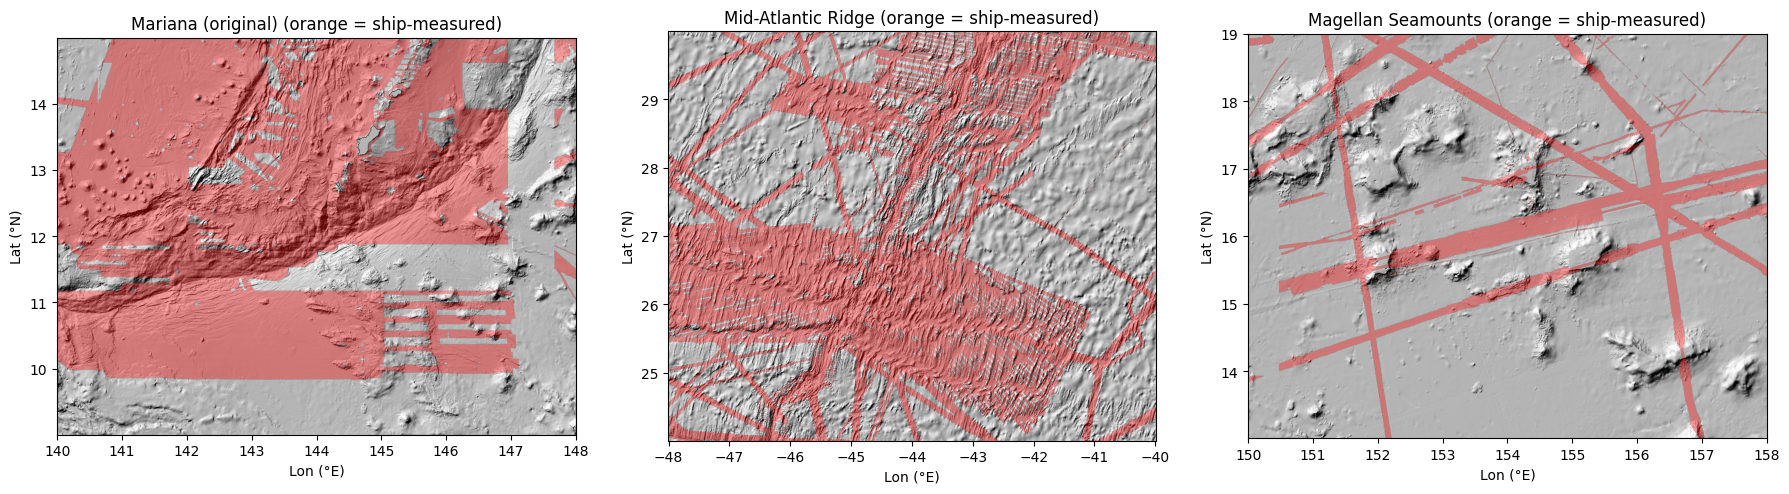

In [2]:
fig, axes = plt.subplots(1, len(data), figsize=(6 * len(data), 4.8))
for ax, (name, (lon, lat, z, ship, dx, dy)) in zip(np.atleast_1d(axes), data.items()):
    ext = [lon[0], lon[-1], lat[0], lat[-1]]; asp = 1 / np.cos(np.deg2rad(lat.mean()))
    ax.imshow(sf.hillshade(np.where(np.isnan(z), np.nanmedian(z), z), dx, dy), extent=ext, origin="lower", cmap="gray", aspect=asp)
    if ship is not None:
        ax.imshow(np.where(ship, 1, np.nan), extent=ext, origin="lower", cmap="autumn", alpha=0.35, aspect=asp)
    ax.set(title=f"{name} (orange = ship-measured)", xlabel="Lon (°E)", ylabel="Lat (°N)")
fig.tight_layout(); fig.savefig(sf.FIG_DIR / "10_regions.png", dpi=150); plt.show()

Mariana (original)   half-power ≈  4.0 km (95% 2.7–8.0); blocks ship 191, sat 139; median depth 4.4 km
Mid-Atlantic Ridge   half-power ≈ 10.8 km (95% 8.5–14.3); blocks ship 11, sat 98; median depth 3.8 km


Magellan Seamounts: too few pure blocks (ship 0, sat 295), can't test here


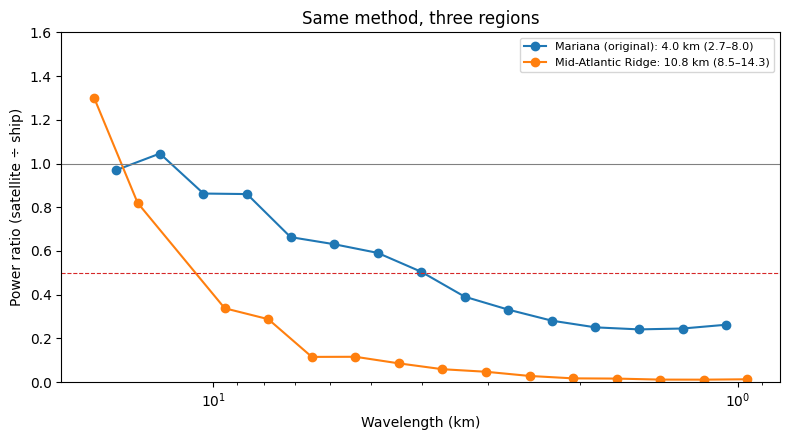

In [3]:
rng = np.random.default_rng(0)
summary = {}; curves = {}
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, (lon, lat, z, ship, dx, dy) in data.items():
    if ship is None: continue
    wl, A, B, _ = sf.block_spectra(z, ship, dx, dy)
    if len(A) < 10 or len(B) < 10:
        print(f"{name}: too few pure blocks (ship {len(A)}, sat {len(B)}), can't test here"); continue
    R = np.exp(B.mean(0) - A.mean(0))
    hp = sf.half_power_wavelength(wl, A, B)
    boots = [sf.half_power_wavelength(wl, A[rng.integers(0, len(A), len(A))], B[rng.integers(0, len(B), len(B))]) for _ in range(500)]
    lo, hi = np.nanpercentile(boots, [2.5, 97.5])
    depth = -np.nanmedian(z) / 1000
    summary[name] = (hp, lo, hi, len(A), len(B), depth)
    ax.semilogx(wl, R, "o-", label=f"{name}: {hp:.1f} km ({lo:.1f}–{hi:.1f})")
    curves[name] = dict(wl=wl.tolist(), R=R.tolist(), hp=hp, lo=lo, hi=hi, depth_km=depth)
    print(f"{name:20s} half-power ≈ {hp:4.1f} km (95% {lo:.1f}–{hi:.1f}); blocks ship {len(A)}, sat {len(B)}; median depth {depth:.1f} km")
ax.axhline(1, c="gray", lw=0.8); ax.axhline(0.5, c="tab:red", ls="--", lw=0.8); ax.invert_xaxis()
ax.set(xlabel="Wavelength (km)", ylabel="Power ratio (satellite ÷ ship)", title="Same method, three regions", ylim=(0, 1.6)); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(sf.FIG_DIR / "10_replication.png", dpi=200); plt.show()

In [4]:
import json
json.dump(curves, open(sf.DATA_DIR / "10_curves.json", "w"), default=float)
print("KEY NUMBERS")
for name, (hp, lo, hi, na, nb_, dep) in summary.items():
    print(f"  {name:20s} half-power {hp:4.1f} km (95% {lo:.1f}–{hi:.1f}), median depth {dep:.1f} km, blocks {na}/{nb_}")

KEY NUMBERS
  Mariana (original)   half-power  4.0 km (95% 2.7–8.0), median depth 4.4 km, blocks 191/139
  Mid-Atlantic Ridge   half-power 10.8 km (95% 8.5–14.3), median depth 3.8 km, blocks 11/98
